# Unit 2 Assignment 4: Statistical Analysis of the Titanic Dataset
**Group members:** Razan, Lamia, Sara, Ahmed

# Task 1: Dataset Exploration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset('titanic')
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [2]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 891
Columns: 15


In [3]:
print(df.columns.tolist())

['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


In [4]:
print(df.dtypes)

survived          int64
pclass            int64
sex                 str
age             float64
sibsp             int64
parch             int64
fare            float64
embarked            str
class          category
who                 str
adult_male         bool
deck           category
embark_town         str
alive               str
alone              bool
dtype: object


In [5]:
print(df.isnull().sum())

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


**Answers:**
1. The dataset has **891 rows** and **15 columns**.
2. Columns: survived, pclass, sex, age, sibsp, parch, fare, embarked, class, who, adult_male, deck, embark_town, alive, alone.
3. Data types: **int** (survived, pclass, sibsp, parch), **float** (age, fare), **text/object** (sex, embarked, who, embark_town, alive), **category** (class, deck), **bool** (adult_male, alone).
4. Missing values: **age = 177** (about 20%), **deck = 688** (about 77%), **embarked = 2**, **embark_town = 2**. All other columns are complete.
5. **Description:** The dataset contains information about 891 passengers of the Titanic, which sank in 1912. For each passenger it records personal details (sex, age), travel details (ticket class, fare, port of embarkation, deck) and family on board (siblings/spouses and parents/children). The column `survived` shows whether the passenger survived (1) or not (0). Some columns repeat the same information in a different form (for example `class` and `pclass`, `alive` and `survived`). The dataset is widely used to practice data analysis and to predict survival with Machine Learning.

# Task 2: Variable Classification

| Variable | Description | Numerical / Categorical | Type |
|---|---|---|---|
| survived | 0 = No, 1 = Yes | Categorical | Nominal |
| pclass | Ticket class 1, 2, 3 | Categorical | Ordinal |
| sex | male / female | Categorical | Nominal |
| age | Age in years | Numerical | Continuous |
| sibsp | Number of siblings/spouses on board | Numerical | Discrete |
| parch | Number of parents/children on board | Numerical | Discrete |
| fare | Ticket price | Numerical | Continuous |
| embarked | Port: C, Q, S | Categorical | Nominal |
| class | First, Second, Third | Categorical | Ordinal |
| who | man / woman / child | Categorical | Nominal |
| adult_male | True / False | Categorical | Nominal |
| deck | Deck A to G | Categorical | Ordinal |
| embark_town | Cherbourg, Queenstown, Southampton | Categorical | Nominal |
| alive | yes / no | Categorical | Nominal |
| alone | True / False | Categorical | Nominal |

- **Nominal:** categories with no order (e.g. sex).
- **Ordinal:** categories with a natural order (e.g. 1st > 2nd > 3rd class).
- **Discrete:** whole-number counts (e.g. number of siblings).
- **Continuous:** measurements that can take any value in a range (e.g. age, fare).

# Task 3: Features and Target

In [6]:
y = df['survived']
X = df[['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']]

print("Target:", y.name)
print("Features:", X.columns.tolist())

Target: survived
Features: ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']


1. **Target variable:** `survived`.
2. **Input features:** pclass, sex, age, sibsp, parch, fare, embarked (also who, adult_male, alone, deck). We do **not** use `alive`, because it is the same as the target, and we skip `class` and `embark_town`, because they repeat `pclass` and `embarked`.
3. **Why is the target called dependent?** Because its value **depends on** the other variables: we want to explain or predict survival using them.
4. **Why are the others called independent?** Because they are the **inputs** we use to make the prediction. They are not predicted by the model; the model uses them to predict the target.

# Task 4: Population and Sampling

In [7]:
random_sample = df.sample(frac=0.3, random_state=42)

stratified_sample = df.groupby('survived').sample(frac=0.3, random_state=42)

print("Population size:", len(df))
print("Random sample size:", len(random_sample))
print("Stratified sample size:", len(stratified_sample))

Population size: 891
Random sample size: 267
Stratified sample size: 268


In [8]:
print("Population:\n", df['survived'].value_counts(normalize=True) * 100)
print("\nRandom sample:\n", random_sample['survived'].value_counts(normalize=True) * 100)
print("\nStratified sample:\n", stratified_sample['survived'].value_counts(normalize=True) * 100)

Population:
 survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

Random sample:
 survived
0    58.801498
1    41.198502
Name: proportion, dtype: float64

Stratified sample:
 survived
0    61.567164
1    38.432836
Name: proportion, dtype: float64


1. **Population:** all **891 passengers** in the dataset.
2. **Sample:** a smaller group taken from the population: here **30% of the passengers** (about 267 rows).
3. **Sizes:** population = 891, random sample = 267, stratified sample = 268 (about 30% of each class, rounded).
4. **The stratified sample** preserves the class distribution better. The population is **61.62% not survived / 38.38% survived**. The stratified sample is almost identical (**61.57% / 38.43%**), while the random sample is a bit different (**58.80% / 41.20%**).
5. **Why representative sampling matters in ML:** if the sample doesn't look like the real data (for example, it has too many survivors), the model learns a **wrong picture** and makes biased predictions. A representative sample makes training and testing **fair and reliable**, especially when one class is smaller than the other.

# Task 5: Descriptive Statistics
We selected **age**, **fare** and **sibsp**.

- Range = Max − Min
- Variance = average of squared distances from the mean
- Standard deviation = √Variance

In [9]:
cols = ['age', 'fare', 'sibsp']

stats = pd.DataFrame({
    'Mean': df[cols].mean(),
    'Median': df[cols].median(),
    'Mode': df[cols].mode().iloc[0],
    'Min': df[cols].min(),
    'Max': df[cols].max(),
    'Range': df[cols].max() - df[cols].min(),
    'Variance': df[cols].var(),
    'Std': df[cols].std()
})

print(stats.round(2))

        Mean  Median   Mode   Min     Max   Range  Variance    Std
age    29.70   28.00  24.00  0.42   80.00   79.58    211.02  14.53
fare   32.20   14.45   8.05  0.00  512.33  512.33   2469.44  49.69
sibsp   0.52    0.00   0.00  0.00    8.00    8.00      1.22   1.10


1. **Highest average:** **fare** (mean = 32.20).
2. **Greatest variability:** **fare** (std = 49.69, variance = 2469.44, range = 512.33).
3. **Mean vs median:**
   - **age:** mean 29.70, median 28.00 → **close**.
   - **fare:** mean 32.20, median 14.45 → **far apart**.
   - **sibsp:** mean 0.52, median 0 → mean is higher.
4. **What it indicates:** age is **almost symmetric** (slightly right-skewed). Fare and sibsp are **right-skewed**: most passengers paid low fares and had few relatives, but a few had very large values that pull the mean up.

# Task 6: Distribution and Outlier Analysis
We chose **age** and **fare**.

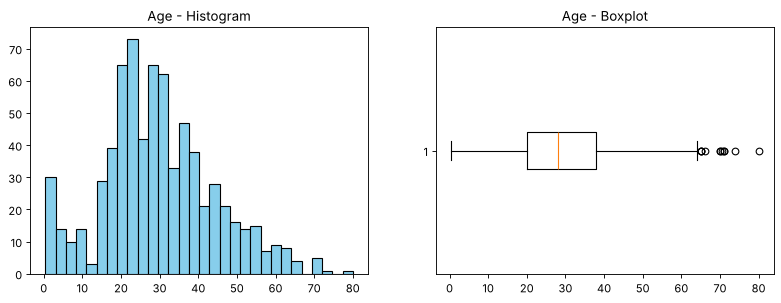

In [10]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(df['age'].dropna(), bins=30, color='skyblue', edgecolor='black')
plt.title('Age - Histogram')

plt.subplot(1, 2, 2)
plt.boxplot(df['age'].dropna(), vert=False)
plt.title('Age - Boxplot')

plt.show()

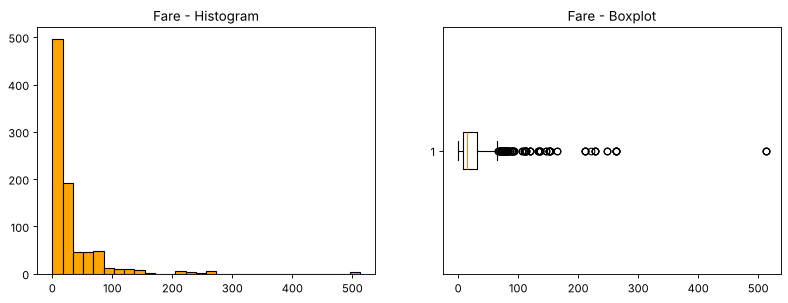

In [11]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(df['fare'], bins=30, color='orange', edgecolor='black')
plt.title('Fare - Histogram')

plt.subplot(1, 2, 2)
plt.boxplot(df['fare'], vert=False)
plt.title('Fare - Boxplot')

plt.show()

In [12]:
for col in ['age', 'fare']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)]
    print(col, "outliers:", len(outliers))

age outliers: 11
fare outliers: 116


1. **Shape:** **Age** is approximately symmetric (slightly skewed to the right). **Fare** is **strongly right-skewed**: most fares are small, with a long tail of expensive tickets.
2. **Outliers:** yes. Using the IQR rule, **age has 11 outliers** (older passengers above about 65 years) and **fare has 116 outliers** (fares above about 65.6, up to 512.33).
3. **The mean is more affected by outliers** than the median.
4. **Explanation from the plots:** in the fare boxplot, many points lie far to the right of the box. These extreme values pull the **mean (32.20)** up, while the **median (14.45)** stays in the middle of the data, at the line inside the box. For age, there are few outliers, so the mean (29.70) and median (28.00) stay close.

# Task 7: Correlation and Covariance Analysis

In [13]:
num = df[['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']]

corr = num.corr()
print(corr.round(2))

          survived  pclass   age  sibsp  parch  fare
survived      1.00   -0.34 -0.08  -0.04   0.08  0.26
pclass       -0.34    1.00 -0.37   0.08   0.02 -0.55
age          -0.08   -0.37  1.00  -0.31  -0.19  0.10
sibsp        -0.04    0.08 -0.31   1.00   0.41  0.16
parch         0.08    0.02 -0.19   0.41   1.00  0.22
fare          0.26   -0.55  0.10   0.16   0.22  1.00


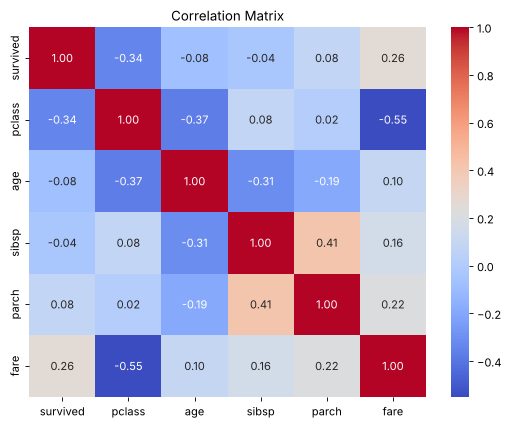

In [14]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

In [15]:
cov = num.cov()
print(cov.round(2))

          survived  pclass     age  sibsp  parch     fare
survived      0.24   -0.14   -0.55  -0.02   0.03     6.22
pclass       -0.14    0.70   -4.50   0.08   0.01   -22.83
age          -0.55   -4.50  211.02  -4.16  -2.34    73.85
sibsp        -0.02    0.08   -4.16   1.22   0.37     8.75
parch         0.03    0.01   -2.34   0.37   0.65     8.66
fare          6.22  -22.83   73.85   8.75   8.66  2469.44


1. **Strongest positive correlation:** **sibsp and parch (0.41)**: passengers traveling with siblings/spouses often also traveled with parents/children. Next is **fare and survived (0.26)**.
   (The strongest relationship overall is **negative**: **pclass and fare (−0.55)**, because a higher class number, 3rd class, means a cheaper ticket.)
2. **Little or no relationship:** **sibsp and survived (−0.04)**, **parch and pclass (0.02)**, **age and survived (−0.08)**: all close to 0.
3. **Difference:** both show whether two variables move together. **Covariance** depends on the variables' units and scale, so it can be any number (e.g. age–fare = 73.85). **Correlation** is the covariance divided by both standard deviations, so it is **always between −1 and 1**.
4. **Correlation is easier to interpret** because it has no units and a fixed scale: we can directly compare strengths (0.41 is stronger than 0.02). Covariance values are hard to compare, because large-scale variables like fare give large numbers even when the relationship is weak.

# Task 8: Statistical Insights

1. **Fare has the largest spread:** std = 49.69 and range = 512.33, much larger than any other variable.
2. **Fare contains the most outliers (116):** it is strongly right-skewed, with a few very expensive tickets, while age has only 11 outliers.
3. **Related variables:** pclass and fare are strongly related (−0.55); higher classes paid more. sibsp and parch are positively related (0.41).
4. **Fare has the highest average (32.20)**, but because of skewness the median (14.45) better describes a typical passenger.
5. **Variables that need preprocessing:** `deck` is 77% missing, `age` is 20% missing, `fare` is skewed with outliers, and only 38% of passengers survived, so the classes are imbalanced.

# Task 9: Statistics for Machine Learning

In [16]:
print(df.groupby('sex')['survived'].mean())
print()
print(df.groupby('pclass')['survived'].mean())

sex
female    0.742038
male      0.188908
Name: survived, dtype: float64

pclass
1    0.629630
2    0.472826
3    0.242363
Name: survived, dtype: float64


1. **Most useful feature: `sex`.** **74%** of women survived compared to only **19%** of men. Among the numerical variables, **pclass** has the strongest correlation with survival (**−0.34**): 63% of 1st class survived versus 24% of 3rd class. **Fare** follows (**0.26**).
2. **Features to remove:**
   - `alive`: it is the **same as the target** (yes/no = survived), which would be cheating (data leakage).
   - `class` and `embark_town`: **duplicates** of `pclass` and `embarked`.
   - `deck`: **77% missing**.
3. **PCA:** looking at the **covariance matrix**, **fare (variance 2469)** and **age (variance 211)** have by far the largest variances, so without scaling they would dominate the first principal components. After standardizing, the **correlation matrix** shows that **pclass and fare (−0.55)** and **sibsp and parch (0.41)** share information, so these groups would contribute most to the main components.
4. **Preprocessing steps:**
   - Fill missing **age** with the median (28) and **embarked** with the mode ('S').
   - Drop **deck**, **alive**, **class** and **embark_town**.
   - Encode categorical variables (e.g. sex → 0/1, one-hot encode embarked).
   - Handle **fare** skewness and outliers (e.g. a log transform).
   - **Scale** the numerical features (standardization), especially before PCA.
   - Use a **stratified** train/test split, since only 38% survived.